In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:
df = pd.read_csv("../dataset/yield_df.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
print(df.head())

   Unnamed: 0     Area         Item  Year  hg/ha_yield  \
0           0  Albania        Maize  1990        36613   
1           1  Albania     Potatoes  1990        66667   
2           2  Albania  Rice, paddy  1990        23333   
3           3  Albania      Sorghum  1990        12500   
4           4  Albania     Soybeans  1990         7000   

   average_rain_fall_mm_per_year  pesticides_tonnes  avg_temp  
0                         1485.0              121.0     16.37  
1                         1485.0              121.0     16.37  
2                         1485.0              121.0     16.37  
3                         1485.0              121.0     16.37  
4                         1485.0              121.0     16.37  


In [4]:
print("Dataset size:", df.shape)

Dataset size: (28242, 8)


In [5]:
print(df.isnull().sum())

Unnamed: 0                       0
Area                             0
Item                             0
Year                             0
hg/ha_yield                      0
average_rain_fall_mm_per_year    0
pesticides_tonnes                0
avg_temp                         0
dtype: int64


In [6]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [7]:
df = df.drop_duplicates()

print("Dataset size after removing duplicates:", df.shape)

Dataset size after removing duplicates: (28242, 8)


In [8]:
print(df.describe())

         Unnamed: 0          Year    hg/ha_yield  \
count  28242.000000  28242.000000   28242.000000   
mean   14120.500000   2001.544296   77053.332094   
std     8152.907488      7.051905   84956.612897   
min        0.000000   1990.000000      50.000000   
25%     7060.250000   1995.000000   19919.250000   
50%    14120.500000   2001.000000   38295.000000   
75%    21180.750000   2008.000000  104676.750000   
max    28241.000000   2013.000000  501412.000000   

       average_rain_fall_mm_per_year  pesticides_tonnes      avg_temp  
count                    28242.00000       28242.000000  28242.000000  
mean                      1149.05598       37076.909344     20.542627  
std                        709.81215       59958.784665      6.312051  
min                         51.00000           0.040000      1.300000  
25%                        593.00000        1702.000000     16.702500  
50%                       1083.00000       17529.440000     21.510000  
75%                       1

In [9]:
crop_yield = df.groupby("Item")["hg/ha_yield"].mean()

print(crop_yield.sort_values(ascending=False))

Item
Potatoes                199801.549579
Cassava                 150479.466993
Sweet potatoes          119057.793772
Yams                    114140.345927
Plantains and others    106041.320144
Rice, paddy              40730.434770
Maize                    36310.070614
Wheat                    30116.267825
Sorghum                  18635.777229
Soybeans                 16731.092771
Name: hg/ha_yield, dtype: float64


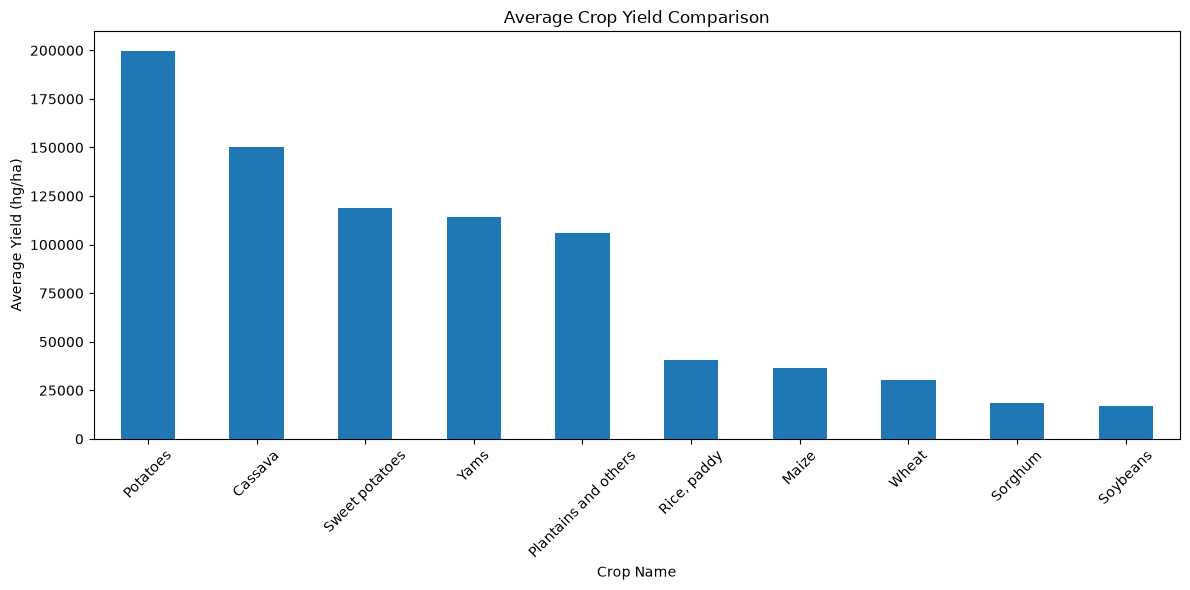

In [10]:
plt.figure(figsize=(12, 6))

crop_yield.sort_values(ascending=False).plot(
    kind="bar",
    title="Average Crop Yield Comparison"
)

plt.xlabel("Crop Name")
plt.ylabel("Average Yield (hg/ha)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

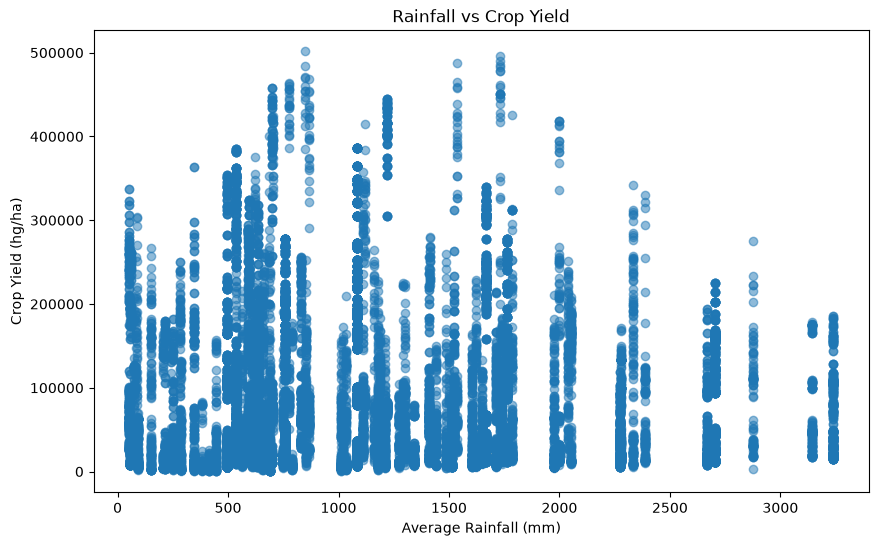

In [11]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["average_rain_fall_mm_per_year"],
    df["hg/ha_yield"],
    alpha=0.5
)

plt.title("Rainfall vs Crop Yield")
plt.xlabel("Average Rainfall (mm)")
plt.ylabel("Crop Yield (hg/ha)")
plt.show()

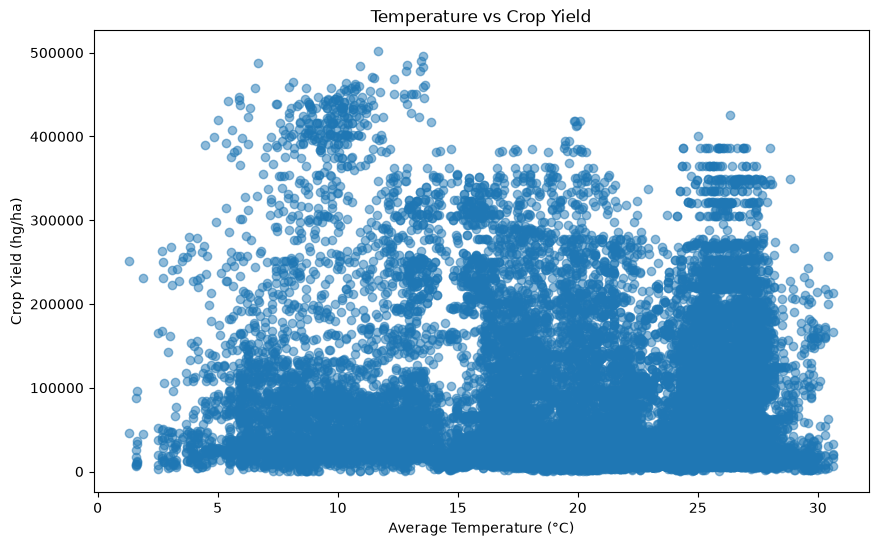

In [12]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["avg_temp"],
    df["hg/ha_yield"],
    alpha=0.5
)

plt.title("Temperature vs Crop Yield")
plt.xlabel("Average Temperature (°C)")
plt.ylabel("Crop Yield (hg/ha)")
plt.show()

In [13]:
print("Number of countries:", df["Area"].nunique())

print("Number of crop types:", df["Item"].nunique())

print("\nCrop types:")
print(df["Item"].unique())

Number of countries: 101
Number of crop types: 10

Crop types:
<ArrowStringArray>
[               'Maize',             'Potatoes',          'Rice, paddy',
              'Sorghum',             'Soybeans',                'Wheat',
              'Cassava',       'Sweet potatoes', 'Plantains and others',
                 'Yams']
Length: 10, dtype: str


In [14]:
df = df.drop(columns=["Unnamed: 0"])

print("Updated dataset shape:", df.shape)

print("\nRemaining columns:")
print(df.columns.tolist())

Updated dataset shape: (28242, 7)

Remaining columns:
['Area', 'Item', 'Year', 'hg/ha_yield', 'average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp']


In [15]:
X = df.drop(columns=["hg/ha_yield"])

y = df["hg/ha_yield"]

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

Input features shape: (28242, 6)
Target shape: (28242,)


In [16]:
from sklearn.preprocessing import OneHotEncoder

print("One-Hot Encoder imported successfully!")

One-Hot Encoder imported successfully!


In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

print("Preprocessing libraries imported successfully!")

Preprocessing libraries imported successfully!


In [18]:
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), ["Area", "Item"])
    ],
    remainder="passthrough"
)

print("Preprocessor created successfully!")

Preprocessor created successfully!


In [19]:
from sklearn.model_selection import train_test_split

print("Train-test split imported successfully!")

Train-test split imported successfully!


In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training input:", X_train.shape)
print("Testing input:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training input: (22593, 6)
Testing input: (5649, 6)
Training target: (22593,)
Testing target: (5649,)


In [21]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Processed training data:", X_train_processed.shape)
print("Processed testing data:", X_test_processed.shape)

Processed training data: (22593, 115)
Processed testing data: (5649, 115)


In [22]:
from sklearn.ensemble import RandomForestRegressor

print("Random Forest imported successfully!")

Random Forest imported successfully!


In [23]:
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train_processed, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [24]:
y_pred = model.predict(X_test_processed)

print("Predictions completed successfully!")
print("First 10 actual values:", y_test[:10].values)
print("First 10 predicted values:", y_pred[:10])

Predictions completed successfully!
First 10 actual values: [ 69220  20000  51206 166986  56319  26163  30708 109771 241650  47500]
First 10 predicted values: [ 70961.5   24360.64  49008.01 163303.94  56065.67  26212.95  30692.22
 109805.73 237555.11  46007.02]


In [25]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Model Evaluation Results
------------------------
MAE: 3466.6454416710926
MSE: 89633723.92575751
RMSE: 9467.508855330292
R2 Score: 0.9876429862991082


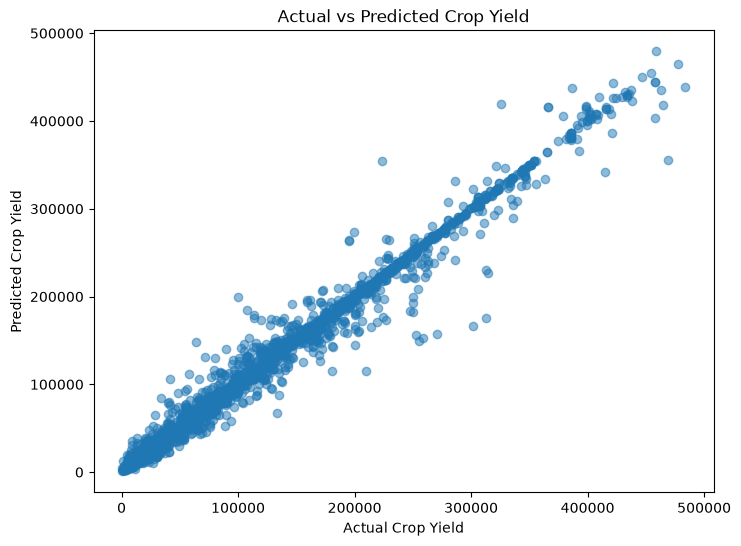

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.xlabel("Actual Crop Yield")
plt.ylabel("Predicted Crop Yield")
plt.title("Actual vs Predicted Crop Yield")

plt.show()

In [27]:
import joblib

joblib.dump(model, "../models/crop_yield_model.pkl")

joblib.dump(preprocessor, "../models/preprocessor.pkl")

print("Model and preprocessor saved successfully!")

Model and preprocessor saved successfully!


In [28]:
import pandas as pd

feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df.head(15))

                                      Feature  Importance
104                categorical__Item_Potatoes    0.369278
101                 categorical__Item_Cassava    0.102436
108          categorical__Item_Sweet potatoes    0.086198
113              remainder__pesticides_tonnes    0.070112
42                    categorical__Area_India    0.058317
112  remainder__average_rain_fall_mm_per_year    0.044208
114                       remainder__avg_temp    0.041791
111                           remainder__Year    0.033028
110                    categorical__Item_Yams    0.027544
97           categorical__Area_United Kingdom    0.017039
48                    categorical__Area_Japan    0.016817
103    categorical__Item_Plantains and others    0.015343
19                   categorical__Area_Canada    0.010619
5                 categorical__Area_Australia    0.010192
69              categorical__Area_New Zealand    0.005591


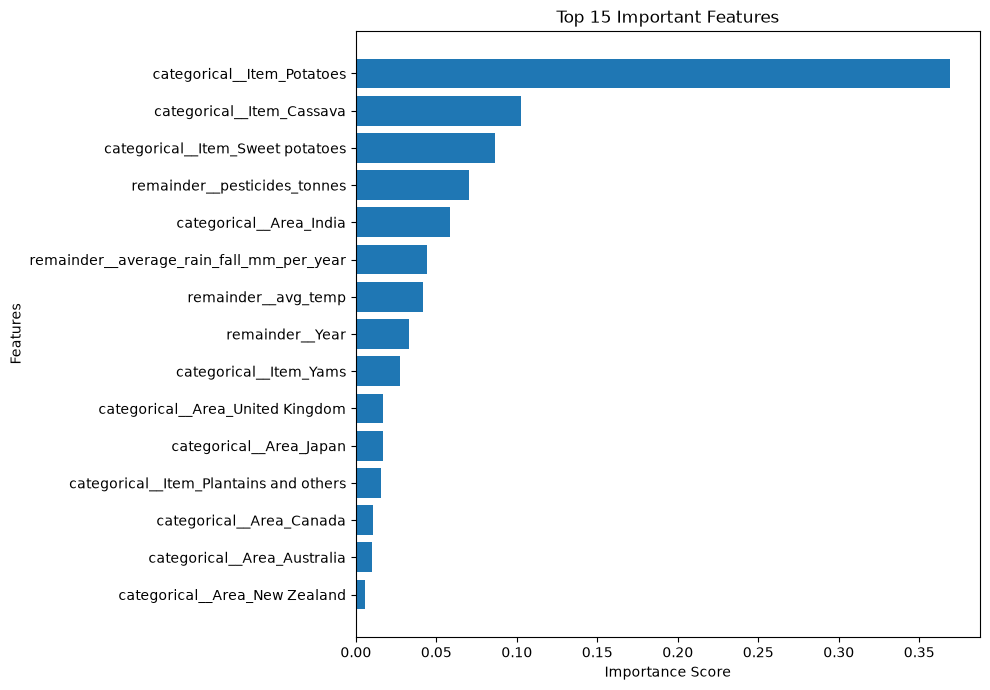

In [29]:
plt.figure(figsize=(10, 7))

top_features = importance_df.head(15)

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Top 15 Important Features")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [1]:
# Time-Based Model Validation

train_df = df[df["Year"] <= 2008].copy()
test_df = df[df["Year"] > 2008].copy()

print("Training data:", train_df.shape)
print("Testing data:", test_df.shape)

print("Training years:",
      train_df["Year"].min(),
      "to",
      train_df["Year"].max())

print("Testing years:",
      test_df["Year"].min(),
      "to",
      test_df["Year"].max())

NameError: name 'df' is not defined

In [2]:
import pandas as pd

# Load the dataset
df = pd.read_csv("../dataset/yield_df.csv")

# Remove unnecessary index column
df = df.drop(columns=["Unnamed: 0"], errors="ignore")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print(df.head())

Dataset loaded successfully!
Dataset shape: (28242, 7)
      Area         Item  Year  hg/ha_yield  average_rain_fall_mm_per_year  \
0  Albania        Maize  1990        36613                         1485.0   
1  Albania     Potatoes  1990        66667                         1485.0   
2  Albania  Rice, paddy  1990        23333                         1485.0   
3  Albania      Sorghum  1990        12500                         1485.0   
4  Albania     Soybeans  1990         7000                         1485.0   

   pesticides_tonnes  avg_temp  
0              121.0     16.37  
1              121.0     16.37  
2              121.0     16.37  
3              121.0     16.37  
4              121.0     16.37  


In [3]:
# Time-Based Model Validation

train_df = df[df["Year"] <= 2008].copy()
test_df = df[df["Year"] > 2008].copy()

print("Training data:", train_df.shape)
print("Testing data:", test_df.shape)

print("Training years:",
      train_df["Year"].min(),
      "to",
      train_df["Year"].max())

print("Testing years:",
      test_df["Year"].min(),
      "to",
      test_df["Year"].max())

Training data: (21991, 7)
Testing data: (6251, 7)
Training years: 1990 to 2008
Testing years: 2009 to 2013


In [4]:
# Separate input features and target

X_train_time = train_df.drop(columns=["hg/ha_yield"])
y_train_time = train_df["hg/ha_yield"]

X_test_time = test_df.drop(columns=["hg/ha_yield"])
y_test_time = test_df["hg/ha_yield"]

print("Training input:", X_train_time.shape)
print("Training target:", y_train_time.shape)

print("Testing input:", X_test_time.shape)
print("Testing target:", y_test_time.shape)

Training input: (21991, 6)
Training target: (21991,)
Testing input: (6251, 6)
Testing target: (6251,)


In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Create a fresh preprocessor
time_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            ["Area", "Item"]
        )
    ],
    remainder="passthrough"
)

# Fit on training data
X_train_time_processed = time_preprocessor.fit_transform(
    X_train_time
)

# Transform testing data
X_test_time_processed = time_preprocessor.transform(
    X_test_time
)

print("Training processed shape:",
      X_train_time_processed.shape)

print("Testing processed shape:",
      X_test_time_processed.shape)

print("Preprocessing completed successfully!")

Training processed shape: (21991, 114)
Testing processed shape: (6251, 114)
Preprocessing completed successfully!


In [6]:
from sklearn.ensemble import RandomForestRegressor

# Create the model
time_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train using 1990–2008 data
time_model.fit(
    X_train_time_processed,
    y_train_time
)

print("Time-based model trained successfully!")

Time-based model trained successfully!


In [7]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Generate predictions
time_predictions = time_model.predict(
    X_test_time_processed
)

# Calculate evaluation metrics
time_mae = mean_absolute_error(
    y_test_time,
    time_predictions
)

time_mse = mean_squared_error(
    y_test_time,
    time_predictions
)

time_rmse = np.sqrt(time_mse)

time_r2 = r2_score(
    y_test_time,
    time_predictions
)

# Display results
print("TIME-BASED MODEL PERFORMANCE")
print("----------------------------")
print("MAE:", time_mae)
print("MSE:", time_mse)
print("RMSE:", time_rmse)
print("R² Score:", time_r2)
print("R² Percentage:", time_r2 * 100, "%")

TIME-BASED MODEL PERFORMANCE
----------------------------
MAE: 10336.350337545991
MSE: 409335423.300898
RMSE: 20232.03952400494
R² Score: 0.9547421278289766
R² Percentage: 95.47421278289767 %


In [8]:
import joblib

# Save time-based model
joblib.dump(
    time_model,
    "../models/crop_yield_time_model.pkl"
)

# Save matching preprocessor
joblib.dump(
    time_preprocessor,
    "../models/crop_yield_time_preprocessor.pkl"
)

print("Time-based model saved successfully!")

Time-based model saved successfully!
